# 01 · A single time series (1-D)

This notebook runs xrMHW on one daily temperature series, the simplest case and
the one to start from if your data come from a mooring, a buoy or a tide gauge.
It shows what each output variable means, turns the daily fields into a table of
events, and checks the result against the reference implementation,
`marineHeatWaves` (Eric Oliver).

The series is one water column of the GLORYS12V1 example, on the slope of the
Grand Bank of Newfoundland, where the column reaches the deepest level (644 m).
We look at the surface first and then compare it with the bottom.

In [1]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pooch
import scipy.ndimage as ndimage
import xarray as xr

import xrMHW

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 11, "axes.titleweight": "bold", "font.size": 9,
    "axes.grid": True, "grid.color": "#e7e6e2", "grid.linewidth": 0.6,
})
INK, INK2 = "#0b0b0b", "#52514e"          # text and neutral lines
BLUE, ORANGE = "#2a78d6", "#eb6834"         # two compared series
# One-hue ramp for the four categories (Moderate, Strong, Severe, Extreme)
CAT_COLORS = ["#d3957f", "#c0583b", "#9d1926", "#5c0e21"]
CAT_NAMES = ["Moderate", "Strong", "Severe", "Extreme"]
print("xrMHW", xrMHW.__version__)

xrMHW 3.0.0


## 1. Get the series

The same download cell appears at the top of every notebook. After the first
download it only reads the local copy (see notebook 00).

In [2]:
EXAMPLE_DATA = pooch.create(
    path=pooch.os_cache("xrmhw"),
    base_url="doi:10.5281/zenodo.22909109/",
    registry={
        "xrmhw_glorys_4d_subset.nc": "md5:5555737e45f1c6cde9f657e50f456693",
        "xrmhw_ostia_sst_3d.nc": "md5:74a2da227394e4463f203f6b388518ee",
    },
)

glorys = xr.open_dataset(EXAMPLE_DATA.fetch("xrmhw_glorys_4d_subset.nc"))

Select one column with `method="nearest"` and keep it as a **Dataset**:
`xrMHW_func` takes a Dataset and the name of the temperature variable. The only
dimension left at the surface is `time`, which is all xrMHW requires.

In [3]:
column = glorys.sel(latitude=44.0, longitude=-48.75, method="nearest").load()
surface = column.isel(depth=0)
print(f"cell at {float(column.latitude):.3f}°N, {-float(column.longitude):.3f}°W")
print(f"surface level {float(surface.depth):.2f} m, "
      f"{surface.sizes['time']} days from {str(surface.time.values[0])[:10]} "
      f"to {str(surface.time.values[-1])[:10]}")
surface

cell at 44.000°N, 48.750°W
surface level 0.49 m, 12017 days from 1993-01-01 to 2025-11-25


<xarray.Dataset> Size: 192kB
Dimensions:    (time: 12017)
Coordinates:
  * time       (time) datetime64[ns] 96kB 1993-01-01 1993-01-02 ... 2025-11-25
    depth      float32 4B 0.494
    latitude   float32 4B 44.0
    longitude  float32 4B -48.75
Data variables:
    thetao     (time) float64 96kB 9.698 8.567 8.581 6.16 ... 5.99 7.162 7.441
Attributes:
    title:       xrMHW example data: GLORYS12V1 4-D subset (Grand Banks slope)
    source:      E.U. Copernicus Marine Service Information (CMEMS), Global O...
    doi:         10.48670/moi-00021
    references:  Lellouche et al. (2021); https://github.com/Gabo2000s/xarray...
    subset:      12x12 cells, all levels, full record
    history:     2026-09-23 subset by make_example_data.py from GLORYS_GrandB...

## 2. Run the detection

`clim_period` sets the baseline years used for the climatology and the threshold.
Here it is 1993–2022, the first 30 full years of the record. Everything else keeps
the Hobday et al. (2016) defaults: the 90th percentile, an 11-day window, 31-day
smoothing, events of at least 5 days, and gaps of up to 2 days joined.

In [4]:
CLIM = (1993, 2022)
out = xrMHW.xrMHW_func(surface, "thetao", clim_period=CLIM)
out

<xarray.Dataset> Size: 481kB
Dimensions:            (time: 12017)
Coordinates:
  * time               (time) datetime64[ns] 96kB 1993-01-01 ... 2025-11-25
    depth              float32 4B 0.494
    latitude           float32 4B 44.0
    longitude          float32 4B -48.75
Data variables:
    mhw_intensity      (time) float32 48kB nan nan nan nan ... nan nan nan nan
    mhw_severity       (time) float32 48kB nan nan nan nan ... nan nan nan nan
    mhw_duration       (time) float32 48kB nan nan nan nan ... nan nan nan nan
    mhw_category       (time) float32 48kB nan nan nan nan ... nan nan nan nan
    mhw_max_intensity  (time) float32 48kB nan nan nan nan ... nan nan nan nan
    mhw_cum_intensity  (time) float32 48kB nan nan nan nan ... nan nan nan nan
    climatology        (time) float32 48kB 4.267 4.183 4.099 ... 7.136 7.033
    mhw_threshold      (time) float32 48kB 7.733 7.61 7.485 ... 10.76 10.66
Attributes: (12/14)
    title:                  xrMHW example data: GLORYS12V1 4-D subset (Grand ...
    source:                 E.U. Copernicus Marine Service Information (CMEMS...
    doi:                    10.48670/moi-00021
    references:             Lellouche et al. (2021); https://github.com/Gabo2...
    subset:                 12x12 cells, all levels, full record
    history:                2026-09-23 subset by make_example_data.py from GL...
    ...                     ...
    mhw_percentile:         90
    mhw_min_duration_days:  5
    mhw_max_gap_days:       2
    mhw_join_method:        post-filter
    mhw_detection_scope:    pointwise (each grid cell is an independent 1-D t...
    software:               xrMHW v3.0.0 (Hobday et al. 2016 definition)

## 3. What the outputs mean

Every output is a daily series on the same time axis as the input.

| Variable            | Units   | Defined on | Meaning                                                                                                  |
| ---------------------| ---------| ------------| ----------------------------------------------------------------------------------------------------------|
| `climatology`       | °C      | every day  | Seasonal mean for that day of the year over the baseline                                                 |
| `mhw_threshold`     | °C      | every day  | Seasonal 90th percentile for that day of the year                                                        |
| `mhw_intensity`     | °C      | event days | Temperature minus climatology                                                                            |
| `mhw_severity`      | 1       | event days | (T − climatology) / (threshold − climatology); 1 at the threshold, 2 at twice its distance from the mean (Sen Gupta et al. 2020) |
| `mhw_category`      | 1       | event days | Category of the whole event: 1 Moderate, 2 Strong, 3 Severe, 4 Extreme (Hobday et al. 2018)              |
| `mhw_duration`      | days    | event days | Length of the event the day belongs to                                                                   |
| `mhw_max_intensity` | °C      | event days | Peak intensity of that event                                                                             |
| `mhw_cum_intensity` | °C days | event days | Intensity summed over that event                                                                         |

The event fields are **NaN outside events**, so `mhw_severity.notnull()` is the
event mask. Duration, category, maximum and cumulative intensity describe the whole
event and are repeated on each of its days; intensity and severity change from
day to day.

Severity is the most useful single field. It is normalised by the local distance
between the threshold and the mean, so a value of 2 means the same thing at the
surface and at 600 m, in the tropics and in the Labrador Sea, which a raw anomaly in
°C does not.

In [5]:
in_event = out["mhw_severity"].notnull()
print(f"days in a marine heatwave: {int(in_event.sum())} of {in_event.size}")
# the first days of the event of winter 2014-15: the fields switch on at its start
out.sel(time=slice("2014-12-14", "2014-12-21")).to_dataframe().drop(
    columns=["depth", "latitude", "longitude"]).round(2)

days in a marine heatwave: 918 of 12017


,mhw_intensity,mhw_severity,mhw_duration,mhw_category,mhw_max_intensity,mhw_cum_intensity,climatology,mhw_threshold
time,,,,,,,,
2014-12-14,NaN,NaN,NaN,NaN,NaN,NaN,5.65,9.44
2014-12-15,NaN,NaN,NaN,NaN,NaN,NaN,5.58,9.39
2014-12-16,NaN,NaN,NaN,NaN,NaN,NaN,5.52,9.33
2014-12-17,4.13,1.09,43.0,3.0,9.7,273.440002,5.45,9.26
2014-12-18,4.96,1.31,43.0,3.0,9.7,273.440002,5.38,9.18
2014-12-19,4.47,1.18,43.0,3.0,9.7,273.440002,5.32,9.10
2014-12-20,3.92,1.04,43.0,3.0,9.7,273.440002,5.25,9.01
2014-12-21,4.17,1.11,43.0,3.0,9.7,273.440002,5.17,8.93


## 4. From daily fields to a table of events

Many analyses need one row per event. The daily fields hold everything needed:
consecutive event days form one event, because events closer than `max_gap` days
have already been joined.

In [6]:
def event_table(out, prefix="mhw"):
    """One row per event from xrMHW's daily fields for a single time series."""
    sev = out[f"{prefix}_severity"]
    labels, _ = ndimage.label(sev.notnull().values)
    time_index = out.indexes["time"]
    intensity = out[f"{prefix}_intensity"].values
    rows = []
    for sl in ndimage.find_objects(labels):
        i0, i1 = sl[0].start, sl[0].stop - 1
        peak = i0 + np.nanargmax(np.abs(intensity[i0:i1 + 1]))
        rows.append({
            "start": time_index[i0].date(), "end": time_index[i1].date(),
            "duration": int(out[f"{prefix}_duration"].values[i0]),
            "peak": time_index[peak].date(),
            "max_intensity": float(out[f"{prefix}_max_intensity"].values[i0]),
            "cum_intensity": float(out[f"{prefix}_cum_intensity"].values[i0]),
            "category": CAT_NAMES[int(out[f"{prefix}_category"].values[i0]) - 1],
        })
    return pd.DataFrame(rows)


events = event_table(out)
print(f"{len(events)} events; median duration {events.duration.median():.0f} days")
events.sort_values("cum_intensity", ascending=False).head(8).round(2)

96 events; median duration 8 days


,start,end,duration,peak,max_intensity,cum_intensity,category
72,2014-12-17,2015-01-28,43,2015-01-14,9.70,273.44,Severe
79,2021-01-07,2021-02-04,29,2021-01-25,8.85,164.43,Severe
88,2024-06-27,2024-07-31,35,2024-07-24,6.47,149.81,Strong
53,2010-12-13,2011-01-06,25,2010-12-27,7.45,140.59,Strong
81,2022-08-13,2022-09-10,29,2022-09-07,4.95,104.07,Moderate
1,1994-06-10,1994-06-23,14,1994-06-16,7.43,92.47,Strong
83,2023-07-13,2023-07-29,17,2023-07-22,7.93,83.81,Severe
82,2022-10-15,2022-10-29,15,2022-10-25,6.33,77.64,Strong


## 5. The classic figure

The figure of Hobday et al. (2016) shows temperature against its climatology and
threshold, with event days shaded. Below, the shading takes the colour of the
category reached **that day** (the integer part of severity), which shows how an
event builds and fades. The dotted lines mark 2, 3 and 4 times the distance from the
climatology to the threshold, the limits of the Strong, Severe and Extreme
categories.

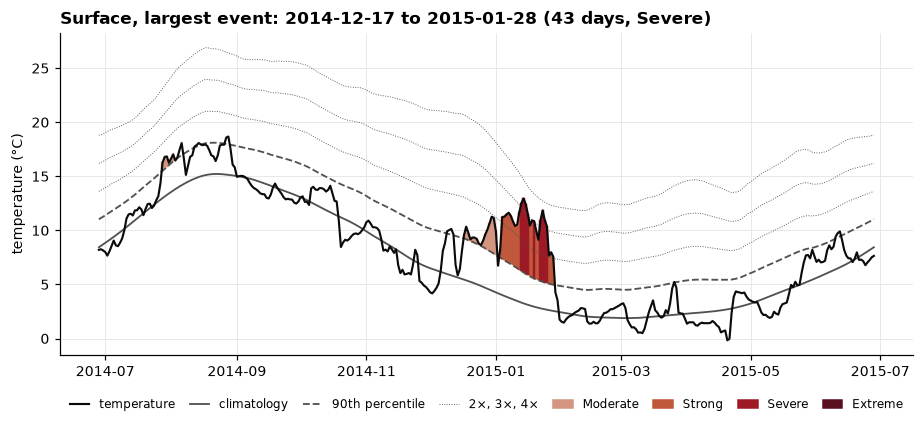

In [7]:
from matplotlib.lines import Line2D
from matplotlib.patches import Patch


def classic_plot(ax, temp, out, start, end, prefix="mhw", title="", legend=True):
    """Temperature, climatology, threshold and event days coloured by daily category."""
    w = slice(start, end)
    t, T = temp.sel(time=w), temp.sel(time=w).values
    clim = out["climatology"].sel(time=w).values
    thr = out[f"{prefix}_threshold"].sel(time=w).values
    sev = out[f"{prefix}_severity"].sel(time=w).values
    daily_cat = np.clip(np.floor(sev), 1, 4)
    for k in range(4):
        on = daily_cat == k + 1
        # one bar per event day, from the threshold up to the temperature
        ax.bar(t.time.values[on], (T - thr)[on], bottom=thr[on], width=1.0,
               color=CAT_COLORS[k], edgecolor=CAT_COLORS[k], lw=0.3)
    for m in (2, 3, 4):
        ax.plot(t.time, clim + m * (thr - clim), color=INK2, lw=0.6, ls=":")
    ax.plot(t.time, clim, color=INK2, lw=1.2)
    ax.plot(t.time, thr, color=INK2, lw=1.2, ls="--")
    ax.plot(t.time, T, color=INK, lw=1.4)
    ax.set_ylabel("temperature (°C)")
    ax.set_axisbelow(True)
    ax.set_title(title, loc="left")
    if legend:
        handles = ([Line2D([], [], color=INK, lw=1.4, label="temperature"),
                    Line2D([], [], color=INK2, lw=1.2, label="climatology"),
                    Line2D([], [], color=INK2, lw=1.2, ls="--", label="90th percentile"),
                    Line2D([], [], color=INK2, lw=0.6, ls=":", label="2×, 3×, 4×")]
                   + [Patch(color=c, label=n) for c, n in zip(CAT_COLORS, CAT_NAMES)])
        ax.legend(handles=handles, ncol=8, fontsize=8, frameon=False, loc="upper center",
                  bbox_to_anchor=(0.5, -0.1), handlelength=1.6, columnspacing=1.2)


top = events.sort_values("cum_intensity", ascending=False).iloc[0]
start = pd.Timestamp(top.peak) - pd.Timedelta(days=200)
end = pd.Timestamp(top.peak) + pd.Timedelta(days=165)
fig, ax = plt.subplots(figsize=(10, 3.8))
classic_plot(ax, surface["thetao"], out, start, end,
             title=f"Surface, largest event: {top.start} to {top.end} "
                   f"({top.duration} days, {top.category})")
plt.show()

## 6. The surface and the bottom

xrMHW works the same way on any number of dimensions, so comparing two depths is
the same call on a Dataset with a `depth` dimension of length 2. Each depth gets its
own climatology and threshold.

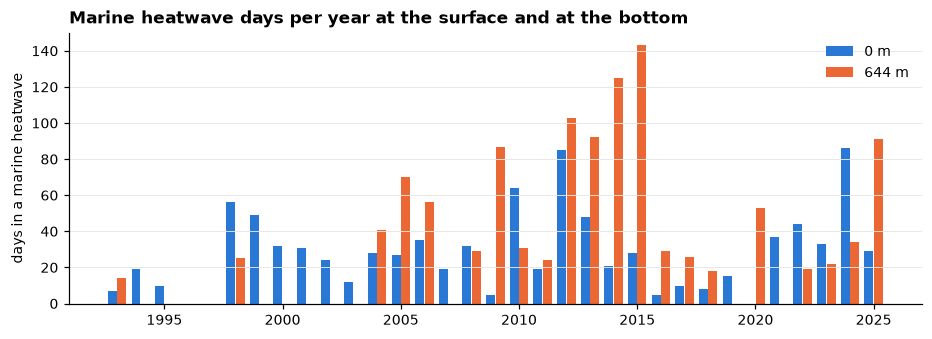

In [8]:
two_levels = column.isel(depth=[0, -1])
out2 = xrMHW.xrMHW_func(two_levels, "thetao", clim_period=CLIM)
days_per_year = out2["mhw_severity"].notnull().groupby("time.year").sum()

depth_labels = [f"{d:.0f} m" for d in two_levels.depth.values]
years = days_per_year.year.values
fig, ax = plt.subplots(figsize=(10, 3.2))
for k, (color, label) in enumerate(zip([BLUE, ORANGE], depth_labels)):
    ax.bar(years + (k - 0.5) * 0.4, days_per_year.isel(depth=k), width=0.38,
           color=color, label=label)
ax.set_ylabel("days in a marine heatwave")
ax.set_title("Marine heatwave days per year at the surface and at the bottom", loc="left")
ax.legend(frameon=False)
ax.grid(axis="x", visible=False)
plt.show()

Each depth has its own climatology and threshold, so events are detected
independently at each level. The two panels below show the same period at both
depths; severity, not the anomaly in °C, is what makes them comparable. Notebook 03
extends this to the whole water column.

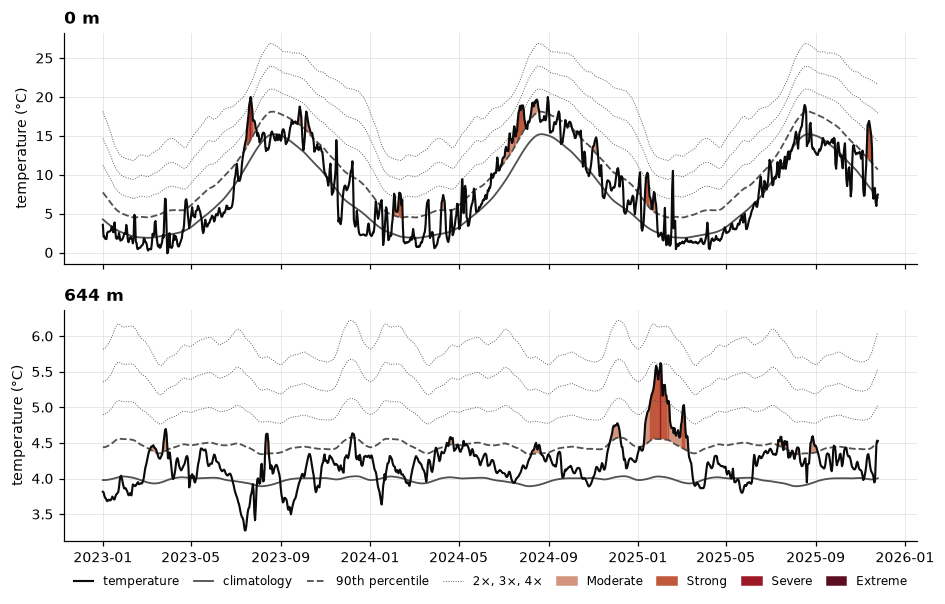

In [9]:
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
for ax, k in zip(axes, range(2)):
    sub = out2.isel(depth=k)
    classic_plot(ax, two_levels["thetao"].isel(depth=k), sub, "2023-01-01", "2025-11-25",
                 title=f"{depth_labels[k]}", legend=(k == 1))
plt.show()

## 7. Validation against the reference implementation

`marineHeatWaves` by Eric Oliver is the reference code for the Hobday et al. (2016)
definition. It is not on PyPI, so the cell below downloads one fixed version of it
with pooch (commit `d7292bf`, the latest at the time of writing) and checks its
checksum.

That version predates NumPy 2. Two small compatibility edits make it run on current
NumPy without changing any result: `np.NaN` becomes `np.nan`, and one assignment
takes the single element of a one-element array (`[0]`). The repository's test
suite uses the same edited copy.

In [10]:
import importlib.util

MHW_COMMIT = "d7292bf08ade0af213fa760b0d7e4adfe5f52894"
mhw_file = pooch.retrieve(
    f"https://raw.githubusercontent.com/ecjoliver/marineHeatWaves/{MHW_COMMIT}/marineHeatWaves.py",
    known_hash="sha256:3f47a51382f68894f34deaf6b466c944cf4f88f92a09a7f00f6d6acd609a0db8",
    fname="marineHeatWaves_d7292bf.py", path=pooch.os_cache("xrmhw"),
)
code = Path(mhw_file).read_text()
code = code.replace("np.NaN", "np.nan").replace(
    "(day_leapYear == day[tt])]", "(day_leapYear == day[tt])][0]")
patched = Path(mhw_file).with_name("marineHeatWaves_d7292bf_numpy2.py")
patched.write_text(code)
spec = importlib.util.spec_from_file_location("marineHeatWaves", patched)
mhw = importlib.util.module_from_spec(spec)
spec.loader.exec_module(mhw)

Run both codes on the surface series. `marineHeatWaves` takes a time vector of
ordinal days and a NumPy array.

In [11]:
t_ord = np.array([d.toordinal() for d in pd.to_datetime(surface.time.values)])
temp = surface["thetao"].values.astype(float)

t0 = time.perf_counter()
ref_events, ref_clim = mhw.detect(t_ord, temp, climatologyPeriod=list(CLIM))
t_ref = time.perf_counter() - t0
t0 = time.perf_counter()
out_again = xrMHW.xrMHW_func(surface, "thetao", clim_period=CLIM).load()
t_xr = time.perf_counter() - t0

ref_table = pd.DataFrame({
    "start": [d.date() if hasattr(d, "date") else d for d in ref_events["date_start"]],
    "end": [d.date() if hasattr(d, "date") else d for d in ref_events["date_end"]],
    "duration": ref_events["duration"],
    "max_intensity": ref_events["intensity_max"],
    "cum_intensity": ref_events["intensity_cumulative"],
    "category": ref_events["category"],
})
same_dates = (len(ref_table) == len(events)
              and (ref_table[["start", "end"]].values == events[["start", "end"]].values).all())
print(f"events: marineHeatWaves {len(ref_table)}, xrMHW {len(events)}; "
      f"identical start and end dates: {same_dates}")
print("max |difference|, climatology:  "
      f"{np.abs(ref_clim['seas'] - out_again['climatology'].values).max():.1e} °C")
print("max |difference|, threshold:    "
      f"{np.abs(ref_clim['thresh'] - out_again['mhw_threshold'].values).max():.1e} °C")
print("max |difference|, max intensity: "
      f"{np.abs(ref_table.max_intensity.values - events.max_intensity.values).max():.1e} °C")
print(f"identical categories: {(ref_table.category.values == events.category.values).all()}")
print(f"runtime: marineHeatWaves {t_ref:.2f} s, xrMHW {t_xr:.2f} s")

events: marineHeatWaves 96, xrMHW 96; identical start and end dates: True
max |difference|, climatology:  4.8e-07 °C
max |difference|, threshold:    9.5e-07 °C
max |difference|, max intensity: 4.7e-07 °C
identical categories: True
runtime: marineHeatWaves 0.08 s, xrMHW 0.03 s


The events are the same, with the same dates and categories. The small differences
in the continuous fields come from xrMHW storing its outputs as 32-bit floats, which
keep about seven significant digits: about 10⁻⁶ °C here, far below the precision of
any ocean temperature product. The test suite of the repository
(`tests/test_against_marineHeatWaves.py`) repeats this comparison on synthetic data
with many parameter combinations.

## 8. Choosing outputs and saving them

By default xrMHW returns all eight variables. `output_vars` selects only those you
need. Asking for continuous fields only (severity, intensity, climatology,
threshold) also skips the loop that computes duration, category and the per-event
intensities, which is the slowest part when events are frequent. Short names are
accepted: `"severity"` stands for `"mhw_severity"`.

The difference is easiest to see on a larger input, here the 33 levels of the
column.

In [13]:
for choice in (None, ["severity", "category"], ["severity", "climatology", "threshold"]): ## 1. "all variables", 
																																																																																										##	2. severity and category
																																																																																										## 3. severity, climatology and threshold
    t0 = time.perf_counter()
    res = xrMHW.xrMHW_func(column, "thetao", clim_period=CLIM, output_vars=choice).load() 
    print(f"{str(choice):45s} {time.perf_counter() - t0:5.2f} s  "
          f"-> {list(res.data_vars)}")

None                                           0.18 s  -> ['mhw_intensity', 'mhw_severity', 'mhw_duration', 'mhw_category', 'mhw_max_intensity', 'mhw_cum_intensity', 'climatology', 'mhw_threshold']
['severity', 'category']                       0.18 s  -> ['mhw_severity', 'mhw_category']
['severity', 'climatology', 'threshold']       0.12 s  -> ['mhw_severity', 'climatology', 'mhw_threshold']


To save results, you can save them to netCDF with compression. The event fields are mostly
NaN, so they compress very well; without compression the file is as large as the
input multiplied by the number of variables extracted.

In [13]:
out_dir = Path("xrmhw_outputs")
out_dir.mkdir(exist_ok=True)
res = xrMHW.xrMHW_func(column, "thetao", clim_period=CLIM).load()

plain = out_dir / "column_uncompressed.nc"
packed = out_dir / "column_zlib.nc"
res.to_netcdf(plain)
res.to_netcdf(packed, encoding={v: {"zlib": True, "complevel": 4} for v in res.data_vars})
print(f"uncompressed {plain.stat().st_size / 1e6:.1f} MB, "
      f"with zlib {packed.stat().st_size / 1e6:.1f} MB")

uncompressed 12.8 MB, with zlib 0.6 MB


## Summary

- `xrMHW_func(ds, "variable", clim_period=(start, end))` works on any Dataset with a
  daily `time` coordinate; here the only other dimension was a depth of length 2.
- Event fields are NaN outside events; severity is the field to compare across
  depths and regions (Sen Gupta et al. 2020).
- With default settings the events match `marineHeatWaves` (Hobday et al., 2016) exactly.
- `output_vars` and compressed output keep runs fast and files small.

Next: **02 · Sea surface maps**.

### References

- Hobday, A. J., et al. (2016). A hierarchical approach to defining marine heatwaves. *Progress in Oceanography*, 141, 227–238. https://doi.org/10.1016/j.pocean.2015.12.014
- Hobday, A. J., et al. (2018). Categorizing and naming marine heatwaves. *Oceanography*, 31(2), 162–173. https://doi.org/10.5670/oceanog.2018.205
- Sen Gupta, A., et al. (2020). Drivers and impacts of the most extreme marine heatwave events. *Scientific Reports*, 10, 19359. https://doi.org/10.1038/s41598-020-75445-3
- Oliver, E. C. J. marineHeatWaves. https://github.com/ecjoliver/marineHeatWaves
- Data: E.U. Copernicus Marine Service Information, https://doi.org/10.48670/moi-00021